## Analyse : Quels sont les éléments naturels d'une voie déterminants dans sa cotation ?

## Import des librairies

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob
import os
import re
import shutil
import subprocess
import sys
import unicodedata
import subprocess, time, re
from datetime import datetime
import bambi as bmb
import arviz as az

g++ not available, if using conda: `conda install gxx`


## 2. Import des données

In [2]:
df = pd.read_csv("annotation_finale_ponderee.csv")
df

C:\Users\lunag\AppData\Local\Temp\ipykernel_35452\1127046363.py:1: DtypeWarning: Columns (31) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("annotation_finale_ponderee.csv")


,document_id,title,title_prefix,quality,activities,climbing_outdoor_type,global_rating,engagement_rating,risk_rating,equipment_rating,...,arête_ponderation,couloir_ponderation,trou_ponderation,réglette_ponderation,cannelure_ponderation,goutte_eau_ponderation,plat_ponderation,bac_ponderation,éperon_ponderation,crochet_ponderation
0,1948176,Triangle des Coutchets - Soleil d'automne,Pic des Coutchets,medium,rock_climbing,multi,TD-,NaN,NaN,P2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1948176,Triangle des Coutchets - Soleil d'automne,Pic des Coutchets,medium,rock_climbing,multi,TD-,NaN,NaN,P2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1948176,Triangle des Coutchets - Soleil d'automne,Pic des Coutchets,medium,rock_climbing,multi,TD-,NaN,NaN,P2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1948176,Triangle des Coutchets - Soleil d'automne,Pic des Coutchets,medium,rock_climbing,multi,TD-,NaN,NaN,P2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1944609,Capricho,Aiguille de la Canalona,medium,rock_climbing,multi,D+,NaN,NaN,P2+,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42856,53893,Voie Directe,Miroir d'Argentine,fine,rock_climbing,multi,D,II,NaN,P2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
42857,53893,Voie Directe,Miroir d'Argentine,fine,rock_climbing,multi,D,II,NaN,P2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
42858,53893,Voie Directe,Miroir d'Argentine,fine,rock_climbing,multi,D,II,NaN,P2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
42859,53893,Voie Directe,Miroir d'Argentine,fine,rock_climbing,multi,D,II,NaN,P2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 3. Manipulation des données

In [3]:
ordre_cotations = [
    "1a", "1b", "1b+", "1c+", 
    "2a", "2a+", "2b", "2b+", "2c", "2c+", 
    "3a", "3a+", "3b", "3b+", "3c", "3c+", 
    "4a", "4a+", "4b", "4b+", "4c", "4c+", 
    "5a", "5a+", "5b", "5b+", "5c", "5c+", 
    "6a", "6a+", "6b", "6b+", "6c", "6c+",
    "7a", "7a+", "7b", "7b+", "7c", "7c+", 
    "8a", "8a+", "8b", "8b+", "8c", "8c+",
    "9a+"
]

In [4]:
# Ordre des cotations

df["difficulty"] = pd.Categorical(
    df["difficulty"],
    categories=ordre_cotations,
    ordered=True
)

In [ ]:
# Fréquents : gardés en compte numérique, plafonnés à 3
elements_frequents = [
    "dalle", "fissure", "dièdre", "traversée", "surplomb",
    "dévers", "cheminée", "vire", "arête", "pilier", "terrasse", "éperon"
]

# Intermédiaires : binarisés en présence/absence
elements_intermediaires = [
    "écailles", "trou", "couloir", "cannelure", "réglette",
    "goutte_eau", "crochet", "bac", "plat", "petite_prise"
]

# Ultra-rares : exclus du modèle
elements_rares = [
    "pince", "mono_doigt", "bi_doigt", "contrefort", "corniche",
    "épaule", "inversee", "fissure-dièdre"
]

# --- Construction du dataset d'analyse (df reste intact) ---
df_model = df.copy()

# 1. Fréquents : compte numérique plafonné à 3
for e in elements_frequents:
    df_model[f"nb_{e}"] = pd.to_numeric(df_model[f"nb_{e}"]).clip(upper=3)

# 2. Intermédiaires : binarisation en pres_<element>
for e in elements_intermediaires:
    df_model[f"pres_{e}"] = (pd.to_numeric(df_model[f"nb_{e}"]) > 0).astype(int)

# 3. Sélection des colonnes finales : variables du modèle + identifiants
colonnes_modele = (
    [f"nb_{e}"  for e in elements_frequents] +
    [f"pres_{e}" for e in elements_intermediaires]
)
df_model = df_model[colonnes_modele + ["difficulty", "document_id", 'log_nb_terms_description', 'termes_ordonnes']].copy()

# 4. Suppression des lignes incomplètes (s'il y a des NaN résiduels)
df_model = df_model.dropna(subset=colonnes_modele + ["difficulty"]).reset_index(drop=True)

## 4. Analyse

In [6]:
# ============================================================
# PARAMÈTRES À ADAPTER
# ============================================================
COL_COTATION = "difficulty"                 # cotation française (6a, 6a+...)
COL_VOIE = "document_id"
PREDICTEURS = ['nb_dalle',
 'nb_fissure',
 'nb_dièdre',
 'nb_traversée',
 'nb_surplomb',
 'nb_dévers',
 'nb_cheminée',
 'nb_vire',
 'nb_arête',
 'nb_pilier',
 'nb_terrasse',
 'nb_éperon',
 'pres_écailles',
 'pres_trou',
 'pres_couloir',
 'pres_cannelure',
 'pres_réglette',
 'pres_goutte_eau',
 'pres_crochet',
 'pres_bac',
 'pres_plat',
 'pres_petite_prise',
 'log_nb_terms_description']   

# Classes de cotation : on borne les extrêmes (rares) -> ici 15 classes
COTATION_MIN = "4c+"                        # tout ce qui est <= devient la classe 1
COTATION_MAX = "7a+"                        # tout ce qui est >= devient la dernière classe

SEPARER_ENTRE_INTRA = False                 # True : effet "à voie égale" et effet "entre voies" séparés
N_VOIES_TEST = 300                         # ex. 300 pour un essai rapide ; None = tout

DOSSIER = "resultats_R"
PREFIXE = os.path.join(DOSSIER, "ordinaleC_Test300_bambi")

MODELE = "mixte"
Z_MAX = 10                            # seuil de winsorisation

In [7]:
# ============================================================
# OUTILS
# ============================================================
def trouver_rscript():
    """Cherche Rscript dans le PATH, puis aux emplacements habituels."""
    chemin = shutil.which("Rscript")
    if chemin:
        return chemin
    candidats = []
    if sys.platform.startswith("win"):
        candidats += sorted(glob.glob(r"C:\R\R-*\bin\Rscript.exe"), reverse=True)
        candidats += sorted(glob.glob(r"C:\R\R-*\bin\x64\Rscript.exe"), reverse=True)
    elif sys.platform == "darwin":
        candidats += ["/usr/local/bin/Rscript", "/opt/homebrew/bin/Rscript",
                      "/Library/Frameworks/R.framework/Resources/bin/Rscript"]
    else:
        candidats += ["/usr/bin/Rscript", "/usr/local/bin/Rscript"]
    for c in candidats:
        if os.path.exists(c):
            return c
    raise FileNotFoundError(
        "Rscript introuvable. Vérifie l'installation de R, ou renseigne le chemin complet de Rscript "
        "dans la variable RSCRIPT ci-dessous."
    )


def nettoyer_nom(nom):
    """Nom de colonne sans accent ni caractère spécial (nécessaire pour les formules R)."""
    s = unicodedata.normalize("NFKD", nom).encode("ascii", "ignore").decode()
    return re.sub(r"\W+", "_", s).strip("_")


ORDRE = [f"{n}{l}{p}" for n in range(1, 10) for l in "abc" for p in ["", "+"]]
RANG = {g: i for i, g in enumerate(ORDRE)}


def cotation_vers_classe(serie):
    """Cotation -> entier croissant (1 = plus facile), extrêmes regroupés."""
    rang = serie.astype("string").str.strip().str.lower().map(RANG).astype(float)
    bas, haut = RANG[COTATION_MIN], RANG[COTATION_MAX]
    return rang.clip(lower=bas, upper=haut) - bas + 1

In [8]:
# ============================================================
# EXTRACTION DES TRANSITIONS (modèle C)
# ============================================================
from collections import Counter
import ast

SEQ_COL = "termes_ordonnes"
SEUIL_TRANSITION = 400          # même seuil que la fusion des classes

def vers_liste(s):
    if isinstance(s, list):
        return s
    if pd.isna(s):
        return []
    try:
        v = ast.literal_eval(s)
        return v if isinstance(v, list) else [s]
    except (ValueError, SyntaxError):
        return [s]

seqs = df_model[SEQ_COL].apply(vers_liste)

# 1) Fréquences globales -> sélection des transitions fréquentes
freq = Counter()
for s in seqs:
    for a, b in zip(s, s[1:]):
        freq[(a, b)] += 1
retenues = sorted([t for t, n in freq.items() if n >= SEUIL_TRANSITION],
                  key=lambda t: -freq[t])
print(f"{len(retenues)} transitions retenues (>= {SEUIL_TRANSITION} occurrences) :")
for (a, b) in retenues:
    print(f"  {a} -> {b} : {freq[(a, b)]}")

# 2) Comptage par longueur -> nouvelles colonnes dans df_model
noms_trans = []
for (a, b) in retenues:
    compte = Counter()
    for idx, s in zip(seqs.index, seqs):
        for x, y in zip(s, s[1:]):
            if (x, y) == (a, b):
                compte[idx] += 1
    nom = nettoyer_nom(f"trans_{a}_vers_{b}")
    df_model[nom] = pd.Series(compte).reindex(df_model.index, fill_value=0).astype(float)
    noms_trans.append(nom)

# 3) Étendre la liste des prédicteurs — tout le reste de la chaîne suit
PREDICTEURS = PREDICTEURS + noms_trans
print(f"\nModèle C : {len(PREDICTEURS)} prédicteurs "
      f"(24 de composition + {len(noms_trans)} de transitions)")

27 transitions retenues (>= 400 occurrences) :
  traversée -> dalle : 938
  dalle -> fissure : 894
  dièdre -> fissure : 795
  traversée -> vire : 795
  traversée -> surplomb : 777
  traversée -> fissure : 747
  fissure -> dalle : 705
  fissure -> fissure : 704
  traversée -> dièdre : 678
  dalle -> traversée : 675
  dalle -> surplomb : 671
  dalle -> dièdre : 668
  fissure -> traversée : 665
  dièdre -> traversée : 623
  dièdre -> dalle : 597
  fissure -> surplomb : 588
  fissure -> dièdre : 586
  dalle -> dalle : 580
  dièdre -> surplomb : 568
  dièdre -> dièdre : 555
  surplomb -> dalle : 545
  surplomb -> traversée : 518
  dalle -> vire : 516
  surplomb -> fissure : 507
  dièdre -> vire : 459
  fissure -> vire : 443
  surplomb -> surplomb : 425

Modèle C : 50 prédicteurs (24 de composition + 27 de transitions)


In [9]:
# ============================================================
# 1. PRÉPARATION DES DONNÉES
# ============================================================

data = pd.DataFrame({
    "classe_cotation": cotation_vers_classe(df_model[COL_COTATION]),
    COL_VOIE: df_model[COL_VOIE],
})
noms_propres = {p: nettoyer_nom(p) for p in PREDICTEURS}
for p, propre in noms_propres.items():
    data[propre] = pd.to_numeric(df_model[p], errors="coerce")
predicteurs = list(noms_propres.values())

data = data.dropna(subset=["classe_cotation"] + predicteurs).copy()
data["classe_cotation"] = data["classe_cotation"].astype(int)
print(f"{len(data)} lignes, {data[COL_VOIE].nunique()} voies, "
      f"{data['classe_cotation'].nunique()} classes de cotation")

if N_VOIES_TEST:
    voies = data[COL_VOIE].drop_duplicates().sample(N_VOIES_TEST, random_state=0)
    data = data[data[COL_VOIE].isin(voies)].copy()
    print(f"Essai rapide : {data[COL_VOIE].nunique()} voies, {len(data)} lignes")

if SEPARER_ENTRE_INTRA:
    nouvelles = []
    for p in predicteurs:
        moyenne = data.groupby(COL_VOIE)[p].transform("mean")
        data[p + "_moy_voie"] = moyenne          # effet "entre voies"
        data[p + "_ecart"] = data[p] - moyenne   # effet "à voie égale"
        nouvelles += [p + "_ecart", p + "_moy_voie"]
    predicteurs = nouvelles

SEUIL_FUSION = 20 if N_VOIES_TEST else 400
effectifs = data["classe_cotation"].value_counts().sort_index()
mapping = {}
for c in effectifs.index:
    if effectifs[c] < SEUIL_FUSION and (c - 1) in effectifs.index:
        mapping[c] = c - 1      # fusion dans la classe inférieure
    else:
        mapping[c] = c
data["classe_cotation"] = data["classe_cotation"].map(mapping)
print("Effectifs des classes après fusion :")
print(data["classe_cotation"].value_counts().sort_index())

os.makedirs(DOSSIER, exist_ok=True)
fichier_csv = os.path.join(DOSSIER, "donnees_pour_R.csv")
data.to_csv(fichier_csv, index=False)

42861 lignes, 9299 voies, 15 classes de cotation
Essai rapide : 300 voies, 1295 lignes
Effectifs des classes après fusion :
classe_cotation
1     162
2      70
4     146
6     194
7      31
8     207
9     139
10    129
11     59
12     70
13     37
14     27
15     24
Name: count, dtype: int64


In [10]:
exclues = {"classe_cotation", COL_VOIE}
predicteurs_modele = [c for c in data.columns if c not in exclues]   # d'abord


# 1) Données : standardisation + winsorisation (comme le faisait le script R)
df_bayes = data.copy()
for p in predicteurs_modele:
    x = df_bayes[p].astype(float)
    z = (x - x.mean()) / x.std()
    df_bayes[p] = z.clip(-10, 10)          # winsorisation à ±10

# 2) Réponse = catégorie ORDONNÉE (indispensable pour la famille cumulative)
categories = sorted(df_bayes["classe_cotation"].unique())
df_bayes["classe_cotation"] = pd.Categorical(df_bayes["classe_cotation"],
                                             categories=categories, ordered=True)
# 3) La voie doit être un facteur, pas un nombre
df_bayes[COL_VOIE] = df_bayes[COL_VOIE].astype("category")

# 4) Priors faiblement informatifs (les mêmes qu'on avait prévus pour brms)
priors = {p: bmb.Prior("Normal", mu=0, sigma=2) for p in predicteurs_modele}
priors["group_specific"] = bmb.Prior(
    "Normal", mu=0, sigma=bmb.Prior("HalfNormal", sigma=2.5)
)
formule = ("classe_cotation ~ " + " + ".join(predicteurs_modele)
           + f" + (1|{COL_VOIE})")
print(formule)

model = bmb.Model(formule, df_bayes, family="cumulative", priors=priors)
print(model)

# 5) Échantillonnage — TEST (300 voies) ; pour le run complet : tune=1000, draws=1500
idata = model.fit(
    draws=1500,
    tune=1000,
    chains=4,
    cores=4,
    inference_method="nutpie",
    random_seed=42,
    progressbar=False
)

# 6) DIAGNOSTICS — les critères de validation
resume = az.summary(idata, ci_prob=0.95, round_to=3)
print(resume)
# À vérifier : r_hat ≈ 1.00 partout (max < 1.01) et ess_bulk > 400
print("Rhat max :", resume["r_hat"].max())

# 7) Export au même format que les scripts R
post = az.summary(idata, var_names=predicteurs_modele, ci_prob=0.95)
res = pd.DataFrame({
    "variable":   post.index,
    "coef":       post["mean"],
    "erreur_std": post["sd"],
    "ic_bas":     post["eti95_lb"],
    "ic_haut":    post["eti95_ub"],
})
res["odds_ratio"] = np.exp(res["coef"])
res.to_csv(f"{PREFIXE}_coefficients.csv", index=False)

sigma_voie = float(az.summary(idata, var_names=[f"1|{COL_VOIE}_sigma"])["mean"].iloc[0])

pd.DataFrame({"n_obs": [len(df_bayes)],
              "n_voies": [df_bayes[COL_VOIE].nunique()],
              "n_classes": [df_bayes["classe_cotation"].nunique()],
              "sd_alea": [sigma_voie],
              "variance_alea": [sigma_voie**2]}
             ).to_csv(f"{PREFIXE}_ajustement.csv", index=False)
print("Résultats écrits :", PREFIXE, "_*.csv")

classe_cotation ~ nb_dalle + nb_fissure + nb_diedre + nb_traversee + nb_surplomb + nb_devers + nb_cheminee + nb_vire + nb_arete + nb_pilier + nb_terrasse + nb_eperon + pres_ecailles + pres_trou + pres_couloir + pres_cannelure + pres_reglette + pres_goutte_eau + pres_crochet + pres_bac + pres_plat + pres_petite_prise + log_nb_terms_description + trans_traversee_vers_dalle + trans_dalle_vers_fissure + trans_diedre_vers_fissure + trans_traversee_vers_vire + trans_traversee_vers_surplomb + trans_traversee_vers_fissure + trans_fissure_vers_dalle + trans_fissure_vers_fissure + trans_traversee_vers_diedre + trans_dalle_vers_traversee + trans_dalle_vers_surplomb + trans_dalle_vers_diedre + trans_fissure_vers_traversee + trans_diedre_vers_traversee + trans_diedre_vers_dalle + trans_fissure_vers_surplomb + trans_fissure_vers_diedre + trans_dalle_vers_dalle + trans_diedre_vers_surplomb + trans_diedre_vers_diedre + trans_surplomb_vers_dalle + trans_surplomb_vers_traversee + trans_dalle_vers_vire +

c:\Python313\Lib\site-packages\bambi\formula.py:112: UserWarning: The intercept is omitted in ordinal families
  warnings.warn("The intercept is omitted in ordinal families")
NUTS[nutpie]: [threshold, nb_dalle, nb_fissure, nb_diedre, nb_traversee, nb_surplomb, nb_devers, nb_cheminee, nb_vire, nb_arete, nb_pilier, nb_terrasse, nb_eperon, pres_ecailles, pres_trou, pres_couloir, pres_cannelure, pres_reglette, pres_goutte_eau, pres_crochet, pres_bac, pres_plat, pres_petite_prise, log_nb_terms_description, trans_traversee_vers_dalle, trans_dalle_vers_fissure, trans_diedre_vers_fissure, trans_traversee_vers_vire, trans_traversee_vers_surplomb, trans_traversee_vers_fissure, trans_fissure_vers_dalle, trans_fissure_vers_fissure, trans_traversee_vers_diedre, trans_dalle_vers_traversee, trans_dalle_vers_surplomb, trans_dalle_vers_diedre, trans_fissure_vers_traversee, trans_diedre_vers_traversee, trans_diedre_vers_dalle, trans_fissure_vers_surplomb, trans_fissure_vers_diedre, trans_dalle_vers_dall

                         mean     sd  eti95_lb  eti95_ub   ess_bulk  ess_tail  \
nb_dalle                0.100  0.091    -0.081     0.277   3523.014  3918.379   
nb_fissure              0.312  0.103     0.111     0.517   3137.181  3738.113   
nb_diedre               0.079  0.106    -0.131     0.284   2698.312  3152.478   
nb_traversee            0.117  0.082    -0.049     0.277   4050.056  4205.639   
nb_surplomb             0.209  0.103     0.012     0.410   2848.883  3520.183   
...                       ...    ...       ...       ...        ...       ...   
1|document_id[1936867]  3.585  0.558     2.519     4.689   7715.116  4614.685   
1|document_id[1937176]  1.898  1.509    -1.121     4.775  11950.612  4915.424   
1|document_id[1937906]  0.977  0.932    -0.827     2.787  10796.233  4350.494   
1|document_id[1938271]  3.278  0.855     1.628     4.972  10582.463  4170.091   
1|document_id[1940693]  1.968  0.985    -0.069     3.769  10335.080  4327.387   

                        r_h

 n_obs  n_voies  n_classes  sd_alea  variance_alea
  1295      300         13 2.312978       5.349866
                     variable   coef  erreur_std  ic_bas  ic_haut  odds_ratio
                     nb_dalle  0.100       0.091  -0.081    0.277       1.105
                   nb_fissure  0.312       0.103   0.111    0.517       1.367
                    nb_diedre  0.079       0.106  -0.131    0.284       1.083
                 nb_traversee  0.117       0.082  -0.049    0.277       1.124
                  nb_surplomb  0.209       0.103   0.012    0.410       1.233
                    nb_devers  0.353       0.062   0.232    0.475       1.423
                  nb_cheminee -0.097       0.070  -0.236    0.042       0.908
                      nb_vire -0.134       0.084  -0.300    0.028       0.874
                     nb_arete -0.090       0.068  -0.225    0.039       0.914
                    nb_pilier -0.003       0.059  -0.120    0.113       0.997
                  nb_terrasse -0.157    

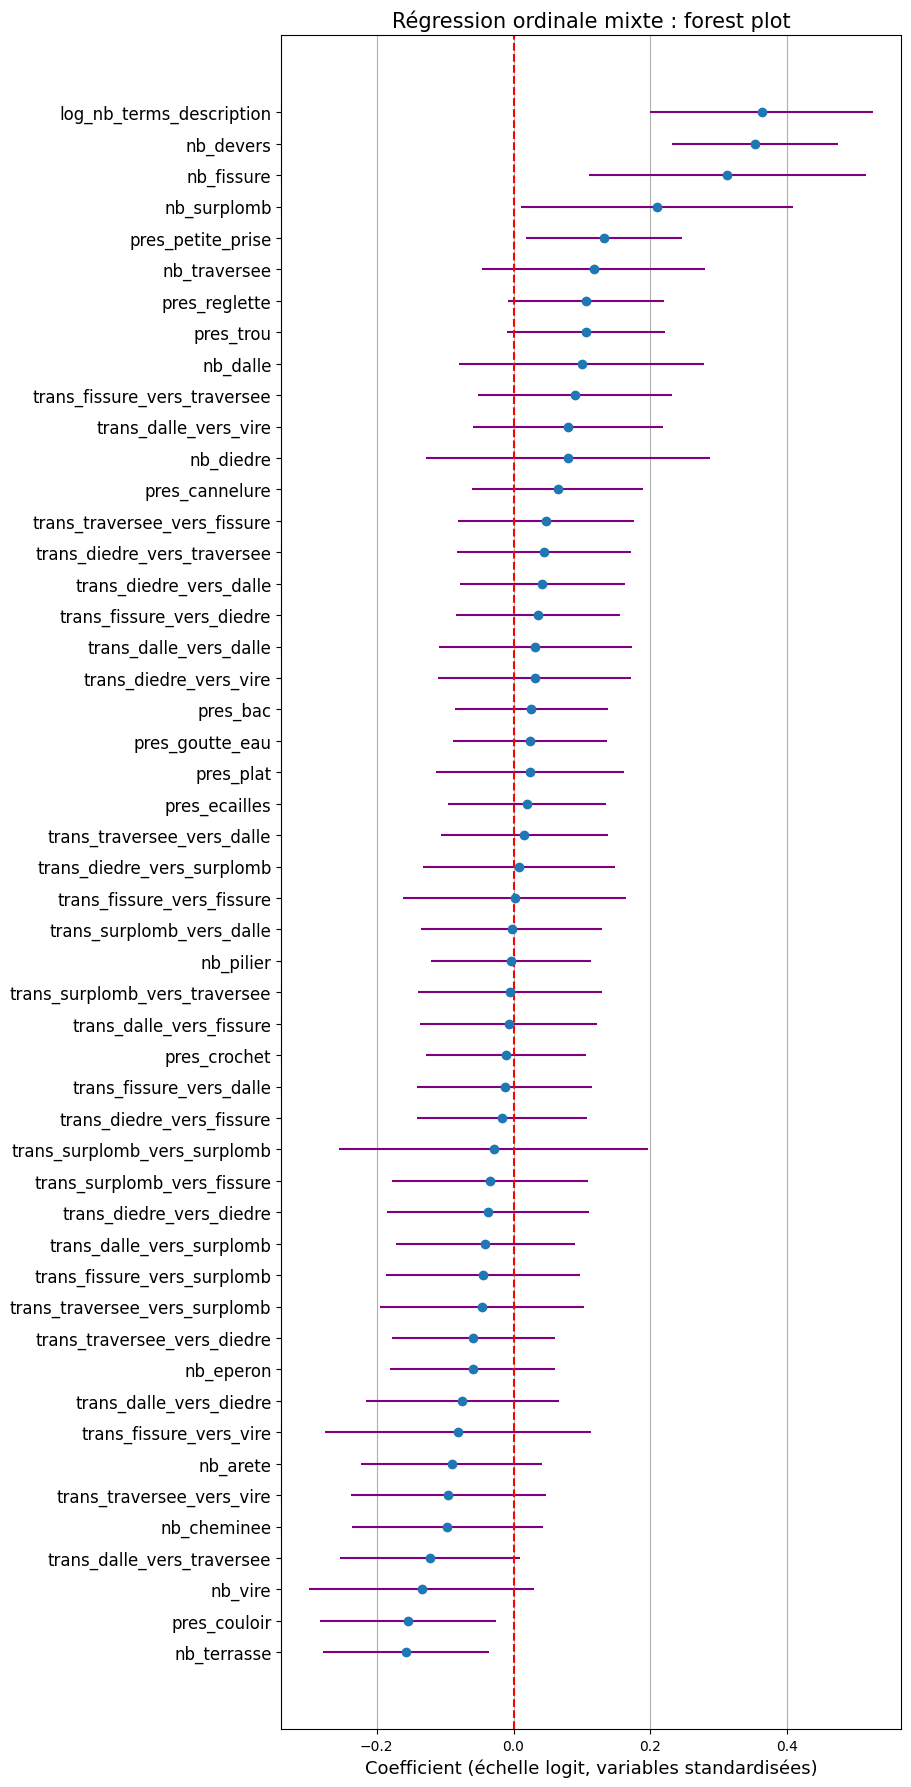

In [11]:
# ============================================================
# 3. RÉSULTATS
# ============================================================
coefs = pd.read_csv(PREFIXE + "_coefficients.csv")
ajust = pd.read_csv(PREFIXE + "_ajustement.csv")
print(ajust.to_string(index=False))
print(coefs.round(3).to_string(index=False))

# Forest plot (coefficients ; positif = cotation plus haute)
coefs = coefs.sort_values("coef").reset_index(drop=True)
y_pos = range(1, len(coefs) + 1)
ci = (coefs["ic_haut"] - coefs["ic_bas"]) / 2

plt.figure(figsize=(8, 0.4 * len(coefs) + 2))
plt.errorbar(coefs["coef"], y_pos, xerr=ci, fmt="o", ecolor="purple")
plt.yticks(y_pos, coefs["variable"], fontsize=12)
plt.axvline(x=0, linestyle="--", color="red")
plt.xlabel("Coefficient (échelle logit, variables standardisées)", fontsize=13)
plt.title("Régression ordinale mixte : forest plot", fontsize=15)
plt.grid(axis="x")